# E-Commerce Product Category Classification

In [1]:
import re

import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

### Load Dataset

In [2]:
df = pd.read_csv("ecommerceDataset.csv", names=['category', 'description'])
df = df[['description', 'category']]

In [3]:
df.shape

(50425, 2)

In [4]:
df.describe().T

,count,unique,top,freq
description,50424,27802,Think & Grow Rich About the Author NAPOLEON HI...,30
category,50425,4,Household,19313


In [5]:
df['category'].value_counts()

category
Household                 19313
Books                     11820
Electronics               10621
Clothing & Accessories     8671
Name: count, dtype: int64

### Missing Values

In [6]:
print("Missing value count:", (len(df) - len(df.dropna())))

Missing value count: 1


In [7]:
df.dropna(inplace = True)
print("Missing value count after dropping null values:", (len(df) - len(df.dropna())))

Missing value count after dropping null values: 0


### Duplicated Values

In [8]:
print("Duplicated values count: ", df.duplicated().sum())

Duplicated values count:  22622


In [9]:
df.drop_duplicates(inplace = True)
df.reset_index(drop = True, inplace = True)
print("Duplicated values count after dropping duplicated values: ", df.duplicated().sum())

Duplicated values count after dropping duplicated values:  0


In [10]:
# Category value counts after dropping missing values and duplicated values
df['category'].value_counts()

category
Household                 10564
Books                      6256
Clothing & Accessories     5674
Electronics                5308
Name: count, dtype: int64

### Labeling Categories

In [11]:
df['category'].unique()

array(['Household', 'Books', 'Clothing & Accessories', 'Electronics'],
      dtype=object)

In [12]:
labels = {'Household': 0, 'Books': 1, 'Clothing & Accessories': 2, 'Electronics': 3}
df['label'] = df['category'].map(labels)

### Text Statistics Before Pre-processing

In [13]:
def text_statistics(df, text_col, label_col, label_mapping=None):
    stats = []

    for label in df[label_col].unique():
        subset = df[df[label_col] == label][text_col]

        word_counts = subset.apply(lambda x: len(x.split()))
        char_counts = subset.apply(len)
        
        # Map label to category name if mapping provided
        class_name = label_mapping.get(label, label) if label_mapping else label

        stats.append({
            "class": label,
            "class_name": class_name,
            "avg_word_count": word_counts.mean(),
            "avg_char_count": char_counts.mean()
        })

    return pd.DataFrame(stats)

In [14]:
label_to_category = {v: k for k, v in labels.items()}

raw_stats = text_statistics(
    df=df,
    text_col="description",
    label_col="label",
    label_mapping=label_to_category
)

raw_stats

,class,class_name,avg_word_count,avg_char_count
0,0,Household,107.005869,661.725861
1,1,Books,139.979380,888.092072
2,2,Clothing & Accessories,72.629186,446.900775
3,3,Electronics,130.456104,825.012811


### Text Pre-processing

In [15]:
def clean_text(text):
    text = str(text)                                   # ensure the input is a string
    text = text.lower()                                # convert to lower case
    text = re.sub(r'\n+', ' ', text)                   # replace newlines with a single space
    text = re.sub(r'https?://\S+|www\.\S+', " ", text) # remove URLs (http, https, www)
    text = re.sub(r'(?<=\w)-(?=\w)', '', text)         # remove hyphen between word chars: "wi-fi" -> "wifi"
    text = re.sub(r'\[.*?\]', '', text)                # remove content inside square brackets
    text = re.sub(r'\b\d+(\.\d+)?\b', ' ', text)       # remove number-only tokens (integers and decimals)
    text = text.replace("_", " ")                      # replace underscores with a space
    text = re.sub(r'[^\w\s]', ' ', text)               # remove remaining punctuation/symbols (keep only words and spaces)
    text = text.encode("ascii", "ignore").decode()     # remove non-ASCII chars (emoji, non-English letters)
    text = re.sub(r'\b[a-z]\b', ' ', text)             # remove single-letter tokens (e.g. "a", "s", "x")
    text = re.sub(r"\s+", " ", text).strip()           # collapse multiple spaces and strip leading/trailing spaces
    return text

In [16]:
df['clean_text'] = df['description'].astype(str).apply(clean_text)

# Save cleaned dataset
df['clean_text'].to_csv("ecommerce_cleaned.csv", index=False, encoding="utf-8")

### Text Statistics After Pre-processing

In [17]:
clean_stats = text_statistics(
    df=df,
    text_col="clean_text",
    label_col="label",
    label_mapping=label_to_category
)

clean_stats

,class,class_name,avg_word_count,avg_char_count
0,0,Household,101.592295,621.117380
1,1,Books,133.571931,832.257832
2,2,Clothing & Accessories,69.951181,421.722242
3,3,Electronics,123.332329,764.398267


In [18]:
comparison_df = raw_stats.merge(
    clean_stats,
    on=["class", "class_name"],
    suffixes=("_before", "_after")
)

comparison_df

,class,class_name,avg_word_count_before,avg_char_count_before,avg_word_count_after,avg_char_count_after
0,0,Household,107.005869,661.725861,101.592295,621.117380
1,1,Books,139.979380,888.092072,133.571931,832.257832
2,2,Clothing & Accessories,72.629186,446.900775,69.951181,421.722242
3,3,Electronics,130.456104,825.012811,123.332329,764.398267


In [19]:
def plot_comparison_stats(comparison_df, metric_col_before, metric_col_after, 
                          metric_display_name, stage_labels=("Before Processing", "After Processing")):
    # Melt the data for better plotting
    melted_data = comparison_df.melt(
        id_vars="class_name",
        value_vars=[metric_col_before, metric_col_after],
        var_name="stage",
        value_name="value"
    )
    
    # Map stage names to readable labels
    stage_mapping = {
        metric_col_before: stage_labels[0],
        metric_col_after: stage_labels[1]
    }
    melted_data["stage"] = melted_data["stage"].map(stage_mapping)
    
    # Create the bar plot
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=melted_data,
        x="class_name",
        y="value",
        hue="stage",
        palette="Set2"
    )
    plt.title(f"{metric_display_name} by Product Category", fontsize=12, fontweight='bold')
    plt.xlabel("Product Category", fontsize=11)
    plt.ylabel(metric_display_name, fontsize=11)
    plt.legend(title="Processing Stage", title_fontsize=10, fontsize=10)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

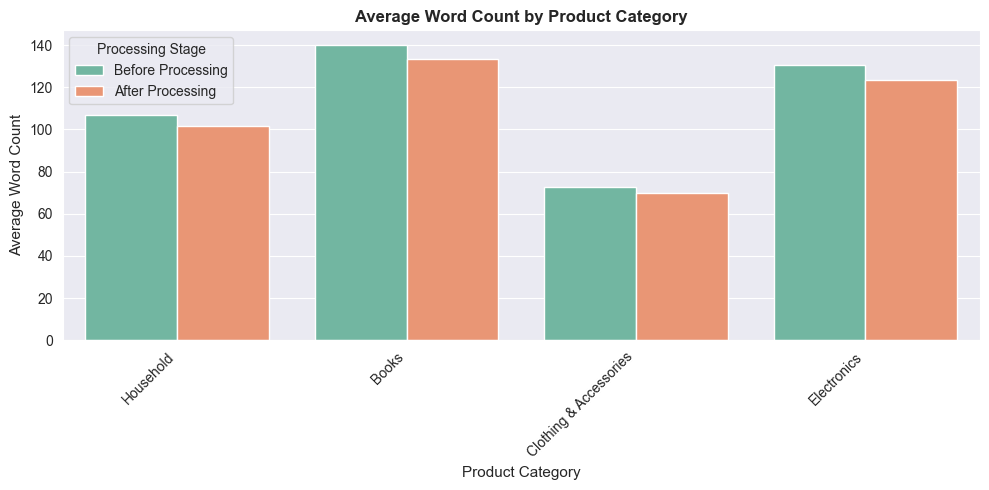

In [20]:
plot_comparison_stats(
    comparison_df,
    metric_col_before="avg_word_count_before",
    metric_col_after="avg_word_count_after",
    metric_display_name="Average Word Count"
)

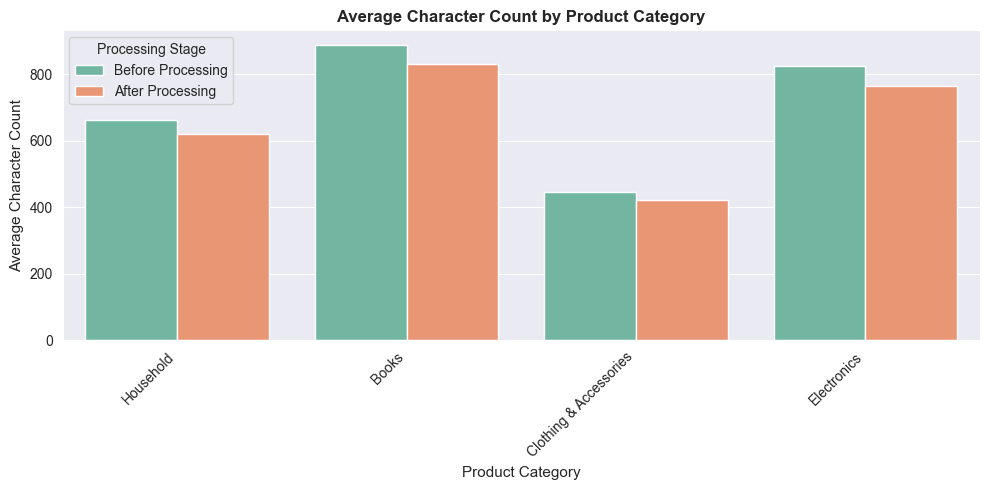

In [21]:
plot_comparison_stats(
    comparison_df,
    metric_col_before="avg_char_count_before",
    metric_col_after="avg_char_count_after",
    metric_display_name="Average Character Count"
)

### Train-Test Split

In [22]:
X = df['clean_text']
y = df['category']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

### TF-IDF Vectorization

In [23]:
tfidf = TfidfVectorizer(
    min_df=5,
    ngram_range=(1,2),
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

### Train and Evaluate Models

In [24]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "SVM (LinearSVC)": LinearSVC(class_weight='balanced', dual='auto'),
    "Random Forest": RandomForestClassifier(n_estimators=20, random_state=42)
}

In [25]:
def evaluate_model(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    print(classification_report(y_true, y_pred, zero_division=0))

    return {
        "model": model_name,
        "accuracy": acc,
        "precision_macro": prec,
        "recall_macro": rec,
        "f1_macro": f1
    }

In [26]:
results = []
trained_models = {}
predictions = {}

for model_name, model in models.items():
    print(f"\n>>> Training {model_name} ...")

    # Train model
    model.fit(X_train_tfidf, y_train)
    trained_models[model_name] = model

    # Get predictions
    y_pred = model.predict(X_test_tfidf)
    predictions[model_name] = y_pred

    # Evaluate model
    result = evaluate_model(y_test, y_pred, model_name)
    results.append(result)


>>> Training Logistic Regression ...
                        precision    recall  f1-score   support

                 Books       0.96      0.93      0.94      1877
Clothing & Accessories       0.97      0.98      0.97      1702
           Electronics       0.93      0.94      0.94      1593
             Household       0.95      0.96      0.95      3169

              accuracy                           0.95      8341
             macro avg       0.95      0.95      0.95      8341
          weighted avg       0.95      0.95      0.95      8341


>>> Training SVM (LinearSVC) ...
                        precision    recall  f1-score   support

                 Books       0.96      0.93      0.95      1877
Clothing & Accessories       0.98      0.98      0.98      1702
           Electronics       0.94      0.94      0.94      1593
             Household       0.95      0.96      0.96      3169

              accuracy                           0.96      8341
             macro avg     

In [27]:
results_df = pd.DataFrame(results)
results_df

,model,accuracy,precision_macro,recall_macro,f1_macro
0,Logistic Regression,0.951804,0.951945,0.951314,0.951568
1,SVM (LinearSVC),0.955401,0.956276,0.953956,0.955062
2,Random Forest,0.921232,0.926258,0.916261,0.920799


### Confusion Matrix's

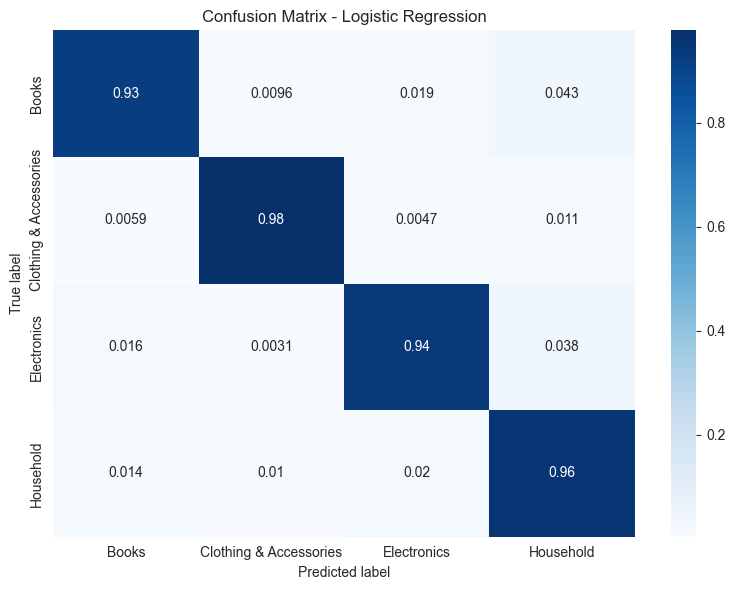

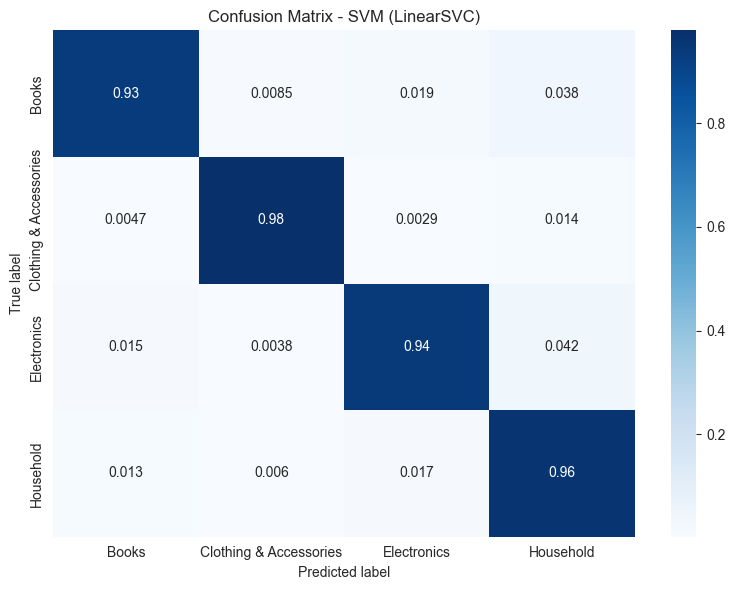

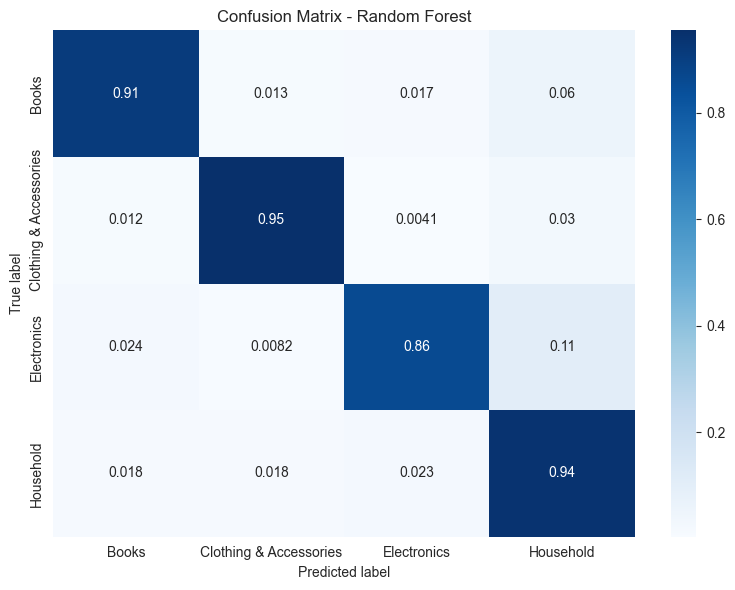

In [28]:
labels = sorted(y_test.unique())

for model_name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=labels, normalize='true')

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()

### Predictions

In [29]:
def predict_text(text, trained_models, vectorizer):
    cleaned = clean_text(text)

    X_tfidf = vectorizer.transform([cleaned])

    print("### Model Predictions ###\n")
    for model_name, model in trained_models.items():
        pred = model.predict(X_tfidf)
        print(f"{model_name}: {pred[0]}")

In [30]:
electronics_text = """
WHY IPAD AIR — iPad Air is powerful, versatile, and comes in a choice of two sizes. Featuring the incredible performance of the M3 chip built for Apple Intelligence and a stunning Liquid Retina display along with Touch ID, advanced cameras, blazing-fast Wi-Fi 6E, and a USB-C connector.
APPLE INTELLIGENCE — Apple Intelligence is the personal intelligence system that helps you write, express yourself, and get things done effortlessly.* With groundbreaking privacy protections integrated into the core of iPad, it gives you peace of mind that no one else can access your data — not even Apple.
PERFORMANCE AND STORAGE — M3 is a powerful chip built for Apple Intelligence that brings amazing performance for advanced creative and product tasks, graphic-intensive games, and smooth multitasking. And with all-day battery life, you can keep working and playing wherever you go.* Choose up to 1TB of storage depending on the room you need for apps, music, movies, and more.*
13-INCH LIQUID RETINA DISPLAY — The gorgeous Liquid Retina display features advanced technologies like P3 wide color, True Tone, and ultralow reflectivity, which make everything look stunning.*
IPADOS + APPS — iPadOS makes iPad more productive, intuitive, and versatile. With iPadOS, run multiple apps at once, use Apple Pencil to write in any text field with Scribble, and edit and share photos.* Stage Manager makes multitasking easy with resizable, overlapping apps and external display support. iPad Air comes with essential apps like Safari, Messages, and Keynote, with over a million more apps designed specifically for iPad available on the App Store.
APPLE PENCIL AND MAGIC KEYBOARD — Apple Pencil Pro transforms iPad Air into an immersive drawing canvas and the world’s best note‑taking device. Apple Pencil (USB-C) is also compatible with iPad Air.* Magic Keyboard for iPad Air delivers an amazing typing experience with a built-in trackpad and 14-key function row, and it doubles as a protective cover on the go.*
ADVANCED CAMERAS — iPad Air features a 12MP Center Stage front camera that’s perfect for video calls and selfies. The 12MP Wide back camera with True Tone flash is perfect for document scanning and capturing photos and 4K videos.
CONNECTIVITY — Wi-Fi 6E gives you fast wireless connections.* Work from almost anywhere with quick transfers of photos, documents, and large video files. Connect to external displays and more with the USB-C connector.
UNLOCK AND PAY WITH TOUCH ID — Touch ID is built into the top button, so you can use your fingerprint to unlock your iPad Air, sign in to apps, and make payments securely with Apple Pay.*
* LEGAL DISCLAIMERS — This is a summary of the main product features. See below to learn more.
"""

predict_text(electronics_text, trained_models, tfidf)

### Model Predictions ###

Logistic Regression: Electronics
SVM (LinearSVC): Electronics
Random Forest: Electronics


In [31]:
book_text = """
Perfect for fans of HBO’s Game of Thrones—a boxed set featuring the first five novels!

An immersive entertainment experience unlike any other, A Song of Ice and Fire has earned George R. R. Martin—dubbed “the American Tolkien” by Time magazine—international acclaim and millions of loyal readers. Now here is the entire monumental cycle:

A GAME OF THRONES
A CLASH OF KINGS
A STORM OF SWORDS
A FEAST FOR CROWS
A DANCE WITH DRAGONS

“One of the best series in the history of fantasy.”—Los Angeles Times

Winter is coming. Such is the stern motto of House Stark, the northernmost of the fiefdoms that owe allegiance to King Robert Baratheon in far-off King’s Landing. There Eddard Stark of Winterfell rules in Robert’s name. There his family dwells in peace and comfort: his proud wife, Catelyn; his sons Robb, Brandon, and Rickon; his daughters Sansa and Arya; and his bastard son, Jon Snow. Far to the north, behind the towering Wall, lie savage Wildings and worse—unnatural things relegated to myth during the centuries-long summer, but proving all too real and all too deadly in the turning of the season.

Yet a more immediate threat lurks to the south, where Jon Arryn, the Hand of the King, has died under mysterious circumstances. Now Robert is riding north to Winterfell, bringing his queen, the lovely but cold Cersei, his son, the cruel, vainglorious Prince Joffrey, and the queen’s brothers Jaime and Tyrion of the powerful and wealthy House Lannister—the first a swordsman without equal, the second a dwarf whose stunted stature belies a brilliant mind. All are heading for Winterfell and a fateful encounter that will change the course of kingdoms.

Meanwhile, across the Narrow Sea, Prince Viserys, heir of the fallen House Targaryen, which once ruled all of Westeros, schemes to reclaim the throne with an army of barbarian Dothraki—whose loyalty he will purchase in the only coin left to him: his beautiful yet innocent sister, Daenerys.

“Long live George Martin . . . a literary dervish, enthralled by complicated characters and vivid language, and bursting with the wild vision of the very best tale tellers.”—The New York Times
"""

predict_text(book_text, trained_models, tfidf)

### Model Predictions ###

Logistic Regression: Books
SVM (LinearSVC): Books
Random Forest: Books


In [32]:
household_text = """
12 Hooks, Large Capacity: Upgrade your organization with our pack of 2 belt hangers, each featuring 12 hooks. That's a total of 24 hooks, providing ample storage for up to 24 belts. Say goodbye to clutter and embrace a neat and organized home with our spacious, wall-mounted belt rack. Effortlessly save space and stay organized!
Advanced 180° Swivel Hooks: Our hanger features a smart 180° rotating hook design. can be adjusted as desired to a vertical wall of 90° or horizontally to both sides, making it convenient for you to better view and choose, make the most of your storage area.
Versatile and Stylish Organization: Not just for belts, our belt rack is a versatile solution for organizing various items in your cloakroom, porch, living room, kitchen, or bedroom, this hanger rack can accommodate a wide range of items such as umbrellas, coats, keys, hats, bags, towels, and more, instantly enhancing the neatness and aesthetic appeal of your rooms.
Elegant Wooden Hangers: We prioritize aesthetics and have deliberately chosen high-quality, eco-friendly wood for our design. Crafted with smooth, durable wood and an elegant black finish, our belt hangers add a touch of sophistication to your living space. Indulge in quality living with our elegant and functional hangers.
Deep "U" Anti-Slip Design: Our deep "U" shaped hooks are meticulously sanded and polished, ensuring there are no sharp edges. They securely hold your belts, tank tops, scarves, and more in place, preventing any slipping or damage. Rest assured, your coats, scarves, towels, and delicate items remain unharmed.
Easy Installation : No more hassle with complex assembly instructions. Our wall hook rack is designed for easy installation, making your organization process a breeze. Simply mark the hole points on the wall, drill, and mount the coat hooks with the provided screws. Enjoy a hassle-free and efficient installation experience.
"""

predict_text(household_text, trained_models, tfidf)

### Model Predictions ###

Logistic Regression: Household
SVM (LinearSVC): Household
Random Forest: Household


In [33]:
clothingAndAccessories_text = """
ULTIMATE PROTECTION – Achiou balaclava is made of high-quality breathable mesh fabric, super comfortable, lightweight, and durable. Protects your head and face from UV rays, dust, and wind.
WARM BREATHABLE & KEEP DRY – Tailored to fit your head and face, ensuring the nose cover doesn’t fall down easily. Suitable for both summer and winter. The breathable balaclava material absorbs sweat and keeps you dry. Fits comfortably under helmets and goggles, keeping your face and head warm
ULTIMATE COMFORT – Provides all-day comfort by keeping you warm and dry. Features stretchy, lightweight, and breathable fabric that protects your face while wicking away moisture. Thermal Dry fabric ensures optimal moisture transfer and dry time
GREAT TO SHARE – Send it to your family, friends, or loved ones as a gift for special occasions like Christmas, New Year’s, Valentine’s Day, Father’s Day, and Mother’s Day! Also an ideal gift for runners, athletes, fitness enthusiasts, hikers, cyclists, or anyone who could benefit from it
VERSATILITY & IDEAL GIFTS – Can be worn as a full face mask, hat, open balaclava, sun shield, half ski mask, neck gaiter, or in saharan and ninja styles. Ideal for skiing, running, riding, fishing, snowboarding, motorcycling, hiking, and climbing. Perfect for women, men, and children. An excellent present choice for your loved ones
"""

predict_text(clothingAndAccessories_text, trained_models, tfidf)

### Model Predictions ###

Logistic Regression: Clothing & Accessories
SVM (LinearSVC): Clothing & Accessories
Random Forest: Clothing & Accessories
